In [1]:
# Data manipulation and numerical computing
import pandas as pd
import numpy as np

# Visualization (full matplotlib package, its pyplot interface and seaborn)
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
import sklearn

# Web app framework
import streamlit as st

# Public holidays by country
import holidays

In [2]:
# Load the sales training data (path relative to the notebooks folder)
ventas_df = pd.read_csv("../data/raw/entrenamiento/ventas.csv")

# Load the competitors' prices training data
competencia_df = pd.read_csv("../data/raw/entrenamiento/competencia.csv")

In [3]:
# Show the first rows of the sales dataframe
ventas_df.head()

,fecha,producto_id,nombre,categoria,subcategoria,precio_base,es_estrella,unidades_vendidas,precio_venta,ingresos
0,2021-10-25,PROD_001,Nike Air Zoom Pegasus 40,Running,Zapatillas Running,115,True,6,118.36,710.16
1,2021-10-25,PROD_002,Adidas Ultraboost 23,Running,Zapatillas Running,135,True,10,136.82,1368.20
2,2021-10-25,PROD_003,Asics Gel Nimbus 25,Running,Zapatillas Running,85,False,2,84.93,169.86
3,2021-10-25,PROD_004,New Balance Fresh Foam X 1080v12,Running,Zapatillas Running,75,False,2,75.42,150.84
4,2021-10-25,PROD_005,Nike Dri-FIT Miler,Running,Ropa Running,35,False,2,35.87,71.74


In [4]:
# Show the first rows of the competitors' prices dataframe
competencia_df.head()

,fecha,producto_id,Amazon,Decathlon,Deporvillage
0,2021-10-25,PROD_001,82.96,111.88,97.43
1,2021-10-25,PROD_002,112.56,108.61,115.58
2,2021-10-25,PROD_003,79.79,78.44,80.11
3,2021-10-25,PROD_004,72.60,67.29,74.45
4,2021-10-25,PROD_005,37.71,33.60,33.07


In [5]:
# Show the column names of the sales dataframe
ventas_df.columns

Index(['fecha', 'producto_id', 'nombre', 'categoria', 'subcategoria',
       'precio_base', 'es_estrella', 'unidades_vendidas', 'precio_venta',
       'ingresos'],
      dtype='str')

In [6]:
# Show the column names of the competitors' prices dataframe
competencia_df.columns

Index(['fecha', 'producto_id', 'Amazon', 'Decathlon', 'Deporvillage'], dtype='str')

In [7]:
# Show shape, data types and non-null counts of the sales dataframe
print(ventas_df.shape)
ventas_df.info()

# Count null values per column
print(ventas_df.isna().sum())

# Count fully duplicated rows and duplicated (fecha, producto_id) keys
print("Full duplicates:", ventas_df.duplicated().sum())
print("Key duplicates:", ventas_df.duplicated(subset=["fecha", "producto_id"]).sum())

(3552, 10)
<class 'pandas.DataFrame'>
RangeIndex: 3552 entries, 0 to 3551
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   fecha              3552 non-null   str    
 1   producto_id        3552 non-null   str    
 2   nombre             3552 non-null   str    
 3   categoria          3552 non-null   str    
 4   subcategoria       3552 non-null   str    
 5   precio_base        3552 non-null   int64  
 6   es_estrella        3552 non-null   bool   
 7   unidades_vendidas  3552 non-null   int64  
 8   precio_venta       3552 non-null   float64
 9   ingresos           3552 non-null   float64
dtypes: bool(1), float64(2), int64(2), str(5)
memory usage: 467.8 KB
fecha                0
producto_id          0
nombre               0
categoria            0
subcategoria         0
precio_base          0
es_estrella          0
unidades_vendidas    0
precio_venta         0
ingresos             0
dtype: int64
Full 

In [8]:
# Descriptive statistics of the numeric columns
display(ventas_df.describe().T)

# Descriptive statistics of the categorical columns
display(ventas_df.select_dtypes(exclude="number").describe().T)

# Frequency of the categories and subcategories
print(ventas_df["categoria"].value_counts())
print(ventas_df["subcategoria"].value_counts())

,count,mean,std,min,25%,50%,75%,max
precio_base,3552.0,123.125000,165.576753,20.00,48.7500,72.50,118.7500,830.00
unidades_vendidas,3552.0,4.878660,6.311020,1.00,2.0000,3.00,5.0000,85.00
precio_venta,3552.0,121.816546,164.017963,19.00,47.2125,71.81,118.2200,854.22
ingresos,3552.0,605.972323,1079.071192,19.46,131.5350,216.57,639.6375,14508.40


,count,unique,top,freq
fecha,3552,148,2021-10-25,24
producto_id,3552,24,PROD_001,148
nombre,3552,24,Nike Air Zoom Pegasus 40,148
categoria,3552,4,Running,1184
subcategoria,3552,16,Zapatillas Running,888
es_estrella,3552,2,False,2516


categoria
Running     1184
Fitness      888
Outdoor      888
Wellness     592
Name: count, dtype: int64
subcategoria
Zapatillas Running       888
Ropa Running             296
Zapatillas Trail         296
Ropa Montaña             296
Mancuernas Ajustables    148
Banco Gimnasio           148
Esterilla Fitness        148
Pesas Casa               148
Bandas Elásticas         148
Pesa Rusa                148
Bicicleta Montaña        148
Mochila Trekking         148
Esterilla Yoga           148
Bloque Yoga              148
Rodillera Yoga           148
Cojín Yoga               148
Name: count, dtype: int64


In [9]:
# Parse the date column and check its range and coverage
fecha_dt = pd.to_datetime(ventas_df["fecha"], errors="coerce")
print("Unparseable dates:", fecha_dt.isna().sum())
print("Range:", fecha_dt.min(), "->", fecha_dt.max())
print(fecha_dt.groupby(fecha_dt.dt.year).agg(["min", "max", "nunique"]))

# Check that every date has the same number of products and vice versa
print(ventas_df.groupby("fecha").size().describe())
print(ventas_df.groupby("producto_id").size().describe())

# Check for negative or zero values in the numeric columns
cols_num = ["precio_base", "unidades_vendidas", "precio_venta", "ingresos"]
print((ventas_df[cols_num] <= 0).sum())

# Check that ingresos equals unidades_vendidas * precio_venta
dif_ingresos = (ventas_df["unidades_vendidas"] * ventas_df["precio_venta"] - ventas_df["ingresos"]).abs()
print("Inconsistent ingresos:", (dif_ingresos > 0.011).sum())

# Check that product attributes are constant for each producto_id
attrs = ["nombre", "categoria", "subcategoria", "precio_base", "es_estrella"]
print(ventas_df.groupby("producto_id")[attrs].nunique().max())

# Ratio between precio_venta and precio_base
print((ventas_df["precio_venta"] / ventas_df["precio_base"]).describe())

Unparseable dates: 0
Range: 2021-10-25 00:00:00 -> 2024-11-30 00:00:00
             min        max  nunique
fecha                               
2021  2021-10-25 2021-11-30       37
2022  2022-10-25 2022-11-30       37
2023  2023-10-25 2023-11-30       37
2024  2024-10-25 2024-11-30       37
count    148.0
mean      24.0
std        0.0
min       24.0
25%       24.0
50%       24.0
75%       24.0
max       24.0
dtype: float64
count     24.0
mean     148.0
std        0.0
min      148.0
25%      148.0
50%      148.0
75%      148.0
max      148.0
dtype: float64
precio_base          0
unidades_vendidas    0
precio_venta         0
ingresos             0
dtype: int64
Inconsistent ingresos: 0
nombre          1
categoria       1
subcategoria    1
precio_base     1
es_estrella     1
dtype: int64
count    3552.000000
mean        0.989296
std         0.035626
min         0.850000
25%         0.978727
50%         0.995976
75%         1.013429
max         1.030000
dtype: float64


In [10]:
# Count global outliers with the IQR rule (1.5 * IQR)
for col in ["unidades_vendidas", "precio_venta", "ingresos"]:
    q1, q3 = ventas_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((ventas_df[col] < q1 - 1.5 * iqr) | (ventas_df[col] > q3 + 1.5 * iqr)).sum()
    print(col, n_out, f"{n_out / len(ventas_df):.2%}")

# Count outliers in unidades_vendidas relative to each product (|z| > 4)
z_unidades = ventas_df.groupby("producto_id")["unidades_vendidas"].transform(lambda s: (s - s.mean()) / s.std())
outliers_df = ventas_df[z_unidades.abs() > 4]
print(len(outliers_df))

# Show in which month-day the product-level outliers happen
print(pd.to_datetime(outliers_df["fecha"]).dt.strftime("%m-%d").value_counts().sort_index())

unidades_vendidas 466 13.12%
precio_venta 296 8.33%
ingresos 405 11.40%
23
fecha
11-24    4
11-25    5
11-26    4
11-29    3
11-30    7
Name: count, dtype: int64


In [11]:
# Show shape, data types and non-null counts of the competitors' prices dataframe
print(competencia_df.shape)
competencia_df.info()

# Count null values per column
print(competencia_df.isna().sum())

# Count fully duplicated rows and duplicated (fecha, producto_id) keys
print("Full duplicates:", competencia_df.duplicated().sum())
print("Key duplicates:", competencia_df.duplicated(subset=["fecha", "producto_id"]).sum())

# Descriptive statistics of the competitors' prices
display(competencia_df.describe().T)

(3552, 5)
<class 'pandas.DataFrame'>
RangeIndex: 3552 entries, 0 to 3551
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   fecha         3552 non-null   str    
 1   producto_id   3552 non-null   str    
 2   Amazon        3552 non-null   float64
 3   Decathlon     3552 non-null   float64
 4   Deporvillage  3552 non-null   float64
dtypes: float64(3), str(2)
memory usage: 201.3 KB
fecha           0
producto_id     0
Amazon          0
Decathlon       0
Deporvillage    0
dtype: int64
Full duplicates: 0
Key duplicates: 0


,count,mean,std,min,25%,50%,75%,max
Amazon,3552.0,118.623407,156.095628,16.85,47.1175,73.180,114.3425,858.3500
Decathlon,3552.0,111.412182,148.508132,15.45,43.2850,66.285,111.1725,867.3375
Deporvillage,3552.0,118.894628,160.216448,16.77,47.3100,72.700,114.9850,932.3250


In [12]:
# Parse the date column and check its range and coverage
fecha_comp_dt = pd.to_datetime(competencia_df["fecha"], errors="coerce")
print("Unparseable dates:", fecha_comp_dt.isna().sum())
print(fecha_comp_dt.groupby(fecha_comp_dt.dt.year).agg(["min", "max", "nunique"]))

# Check that every date has the same number of products and vice versa
print(competencia_df.groupby("fecha").size().describe())
print(competencia_df.groupby("producto_id").size().describe())

# Check for negative or zero prices
cols_comp = ["Amazon", "Decathlon", "Deporvillage"]
print((competencia_df[cols_comp] <= 0).sum())

# Count outliers in each competitor's price with the IQR rule (1.5 * IQR)
for col in cols_comp:
    q1, q3 = competencia_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((competencia_df[col] < q1 - 1.5 * iqr) | (competencia_df[col] > q3 + 1.5 * iqr)).sum()
    print(col, n_out, f"{n_out / len(competencia_df):.2%}")

# Check that both dataframes share exactly the same (fecha, producto_id) keys
claves_ventas = set(zip(ventas_df["fecha"], ventas_df["producto_id"]))
claves_comp = set(zip(competencia_df["fecha"], competencia_df["producto_id"]))
print("Only in ventas:", len(claves_ventas - claves_comp), "| Only in competencia:", len(claves_comp - claves_ventas))

# Compare each competitor's price against our own base and sale prices
cruce_df = ventas_df.merge(competencia_df, on=["fecha", "producto_id"], how="inner")
for col in cols_comp:
    print(col, "/ precio_base:", (cruce_df[col] / cruce_df["precio_base"]).describe()[["min", "mean", "max"]].round(3).to_dict())
    print(col, "/ precio_venta:", (cruce_df[col] / cruce_df["precio_venta"]).describe()[["min", "mean", "max"]].round(3).to_dict())

# Correlation between the competitors' prices
print(competencia_df[cols_comp].corr().round(3))

# Largest day-to-day price change per product and competitor
comp_ord_df = competencia_df.assign(fecha_dt=fecha_comp_dt).sort_values(["producto_id", "fecha_dt"])
for col in cols_comp:
    cambio = comp_ord_df.groupby("producto_id")[col].pct_change().abs()
    print(col, "max change:", round(cambio.max(), 3), "| changes > 30%:", (cambio > 0.3).sum())

Unparseable dates: 0
             min        max  nunique
fecha                               
2021  2021-10-25 2021-11-30       37
2022  2022-10-25 2022-11-30       37
2023  2023-10-25 2023-11-30       37
2024  2024-10-25 2024-11-30       37
count    148.0
mean      24.0
std        0.0
min       24.0
25%       24.0
50%       24.0
75%       24.0
max       24.0
dtype: float64
count     24.0
mean     148.0
std        0.0
min      148.0
25%      148.0
50%      148.0
75%      148.0
max      148.0
dtype: float64


Amazon          0
Decathlon       0
Deporvillage    0
dtype: int64
Amazon 296 8.33%
Decathlon 296 8.33%
Deporvillage 296 8.33%
Only in ventas: 0 | Only in competencia: 0
Amazon / precio_base: {'min': 0.667, 'mean': 0.98, 'max': 1.198}
Amazon / precio_venta: {'min': 0.674, 'mean': 0.991, 'max': 1.287}
Decathlon / precio_base: {'min': 0.73, 'mean': 0.912, 'max': 1.152}
Decathlon / precio_venta: {'min': 0.715, 'mean': 0.923, 'max': 1.219}
Deporvillage / precio_base: {'min': 0.765, 'mean': 0.979, 'max': 1.123}
Deporvillage / precio_venta: {'min': 0.768, 'mean': 0.99, 'max': 1.227}
              Amazon  Decathlon  Deporvillage
Amazon         1.000      0.997         0.998
Decathlon      0.997      1.000         0.999
Deporvillage   0.998      0.999         1.000
Amazon max change: 0.331 | changes > 30%: 2
Decathlon max change: 0.27 | changes > 30%: 0
Deporvillage max change: 0.234 | changes > 30%: 0


In [13]:
# Convert the date column of the sales dataframe to datetime
ventas_df["fecha"] = pd.to_datetime(ventas_df["fecha"])

# Convert the date column of the competitors' prices dataframe to datetime
competencia_df["fecha"] = pd.to_datetime(competencia_df["fecha"])

# Print the resulting dtype and first values of the date column in both dataframes
print(ventas_df["fecha"].dtype)
print(ventas_df["fecha"].head())
print(competencia_df["fecha"].dtype)
print(competencia_df["fecha"].head())

datetime64[us]
0   2021-10-25
1   2021-10-25
2   2021-10-25
3   2021-10-25
4   2021-10-25
Name: fecha, dtype: datetime64[us]
datetime64[us]
0   2021-10-25
1   2021-10-25
2   2021-10-25
3   2021-10-25
4   2021-10-25
Name: fecha, dtype: datetime64[us]


In [14]:
# Merge sales and competitors' prices using fecha and producto_id as keys (one row per key in both dataframes)
df = ventas_df.merge(competencia_df, on=["fecha", "producto_id"], how="left", validate="one_to_one")

# Check the shape and the first rows of the merged dataframe
print(df.shape)
df.head()

(3552, 13)


,fecha,producto_id,nombre,categoria,subcategoria,precio_base,es_estrella,unidades_vendidas,precio_venta,ingresos,Amazon,Decathlon,Deporvillage
0,2021-10-25,PROD_001,Nike Air Zoom Pegasus 40,Running,Zapatillas Running,115,True,6,118.36,710.16,82.96,111.88,97.43
1,2021-10-25,PROD_002,Adidas Ultraboost 23,Running,Zapatillas Running,135,True,10,136.82,1368.20,112.56,108.61,115.58
2,2021-10-25,PROD_003,Asics Gel Nimbus 25,Running,Zapatillas Running,85,False,2,84.93,169.86,79.79,78.44,80.11
3,2021-10-25,PROD_004,New Balance Fresh Foam X 1080v12,Running,Zapatillas Running,75,False,2,75.42,150.84,72.60,67.29,74.45
4,2021-10-25,PROD_005,Nike Dri-FIT Miler,Running,Ropa Running,35,False,2,35.87,71.74,37.71,33.60,33.07


# Exploratory Data Analysis (EDA)

In this section we explore the `df` dataframe (sales merged with competitors' prices) to understand how sales behave and how our prices are positioned against the market. All the visualizations are built with **Seaborn**.

The data covers the autumn campaign (from October 25th to November 30th) of the years 2021 to 2024, so it includes the **Black Friday** of each year.

## Analyses and visualizations

1. **Time evolution by year**: one independent line chart for each year with the daily sum of units sold, marking the Black Friday date. It shows the effect of the campaign and whether the pattern repeats from year to year.
2. **Units sold by day of the week**: bar chart from Monday to Sunday to detect whether there is weekly seasonality.
3. **Units sold by category**: bar chart to identify which categories concentrate most of the sales.
4. **Units sold by subcategory**: same analysis at a more granular level, to see which product lines drive each category.
5. **Top 10 products**: bar chart with the best-selling products, to learn how concentrated the volume is in a few products.
6. **Price distribution density**: comparison of the density of our sale price against Amazon's price, used as the competition reference. A logarithmic scale is used because prices range from about 20 € to about 850 €. It shows whether we are positioned above, below or in line with the market.

DatetimeIndex(['2021-11-26', '2022-11-25', '2023-11-24', '2024-11-29'], dtype='datetime64[us]', freq=None)


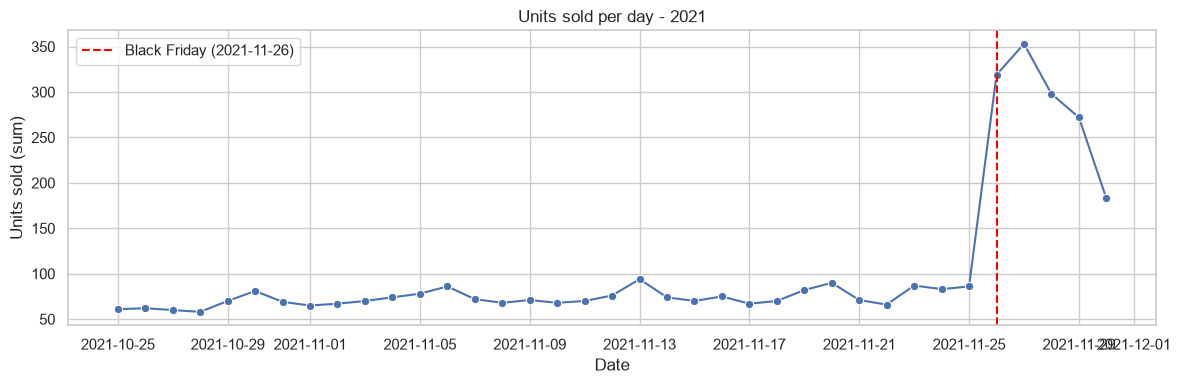

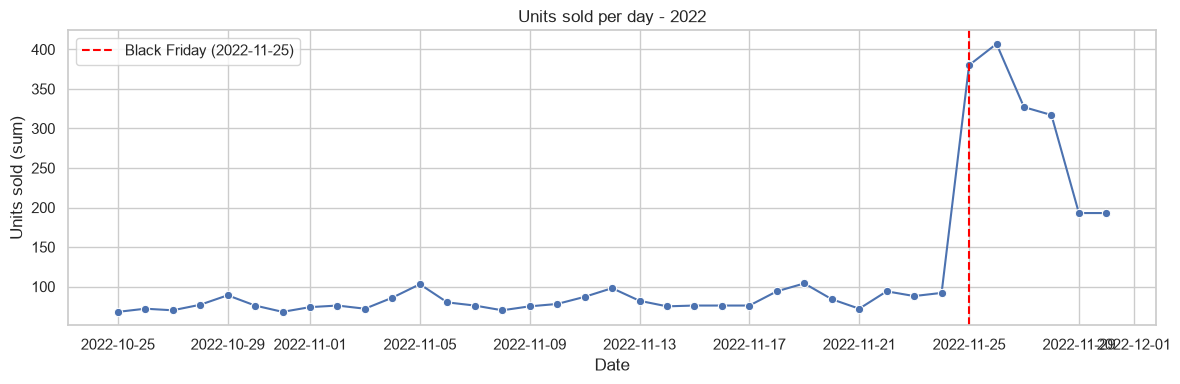

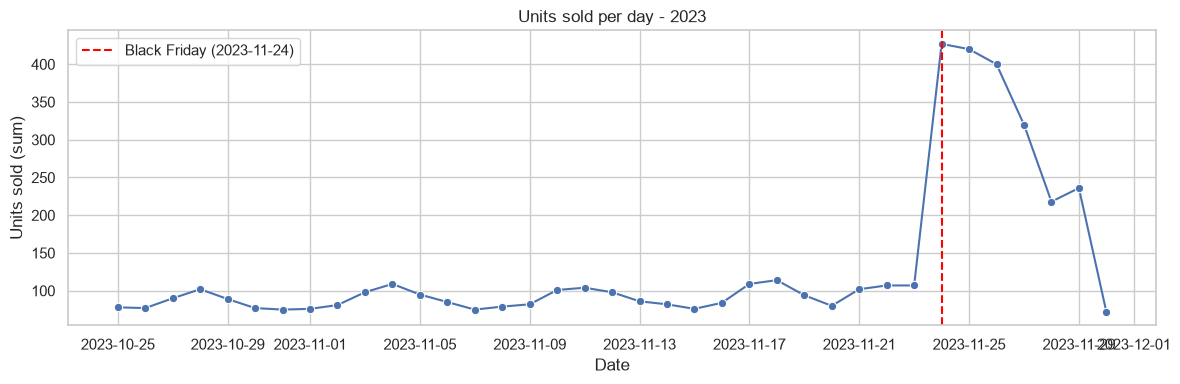

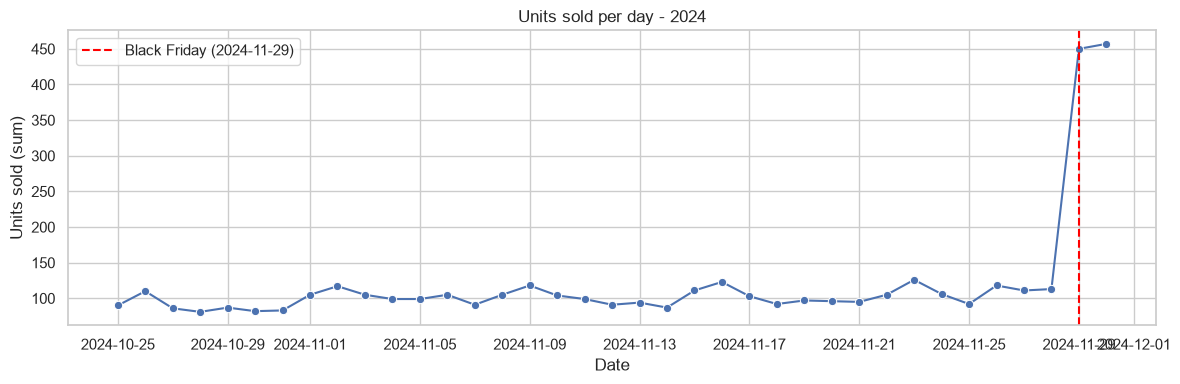

In [15]:
# Set a common seaborn theme for all the exploratory plots
sns.set_theme(style="whitegrid", context="notebook")

# Compute the Black Friday date of each year (day after the 4th Thursday of November)
black_fridays = pd.date_range("2021-01-01", "2024-12-31", freq="WOM-4THU") + pd.Timedelta(days=1)
black_fridays = black_fridays[black_fridays.month == 11]
print(black_fridays)

# Aggregate the units sold per day
unidades_dia = df.groupby("fecha", as_index=False)["unidades_vendidas"].sum()
unidades_dia["año"] = unidades_dia["fecha"].dt.year

# Plot one time series per year with the Black Friday marked
for año, datos in unidades_dia.groupby("año"):
    fig, ax = plt.subplots(figsize=(12, 4))
    sns.lineplot(data=datos, x="fecha", y="unidades_vendidas", marker="o", ax=ax)

    # Mark the Black Friday of this year with a vertical line
    bf = black_fridays[black_fridays.year == año][0]
    ax.axvline(bf, color="red", linestyle="--", label=f"Black Friday ({bf:%Y-%m-%d})")

    ax.set_title(f"Units sold per day - {año}")
    ax.set_xlabel("Date")
    ax.set_ylabel("Units sold (sum)")
    ax.legend()
    plt.tight_layout()
    plt.show()

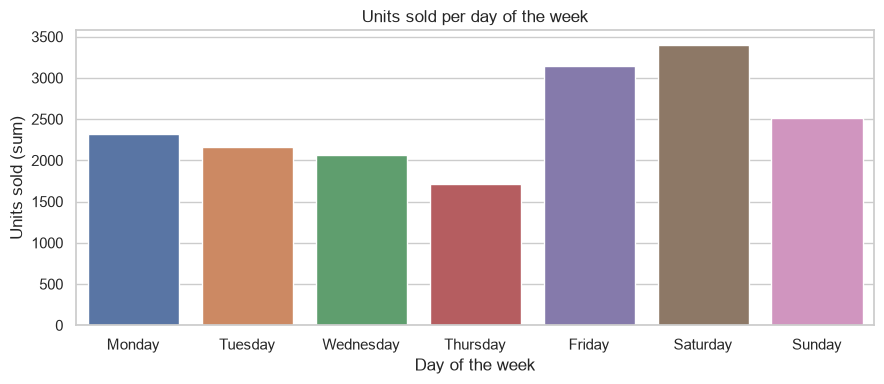

In [16]:
# Sum the units sold per day of the week (ordered Monday to Sunday)
orden_dias = [0, 1, 2, 3, 4, 5, 6]
nombres_dias = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
unidades_semana = df.groupby(df["fecha"].dt.dayofweek)["unidades_vendidas"].sum().reindex(orden_dias)
unidades_semana.index = nombres_dias

# Plot the units sold per day of the week
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=unidades_semana.index, y=unidades_semana.values, hue=unidades_semana.index, legend=False, ax=ax)
ax.set_title("Units sold per day of the week")
ax.set_xlabel("Day of the week")
ax.set_ylabel("Units sold (sum)")
plt.tight_layout()
plt.show()

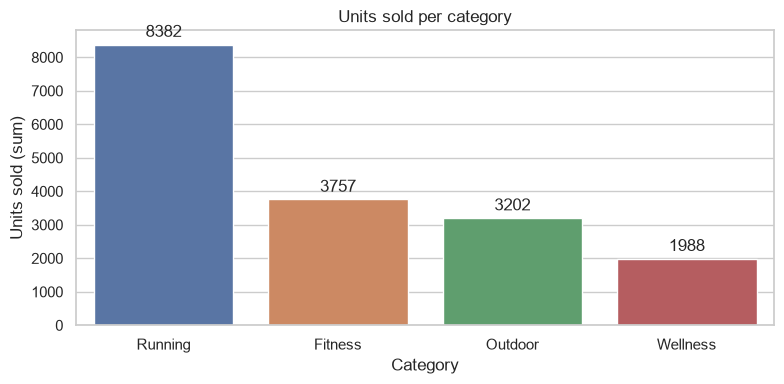

In [17]:
# Sum the units sold per category
unidades_categoria = df.groupby("categoria", as_index=False)["unidades_vendidas"].sum().sort_values("unidades_vendidas", ascending=False)

# Plot the units sold per category
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=unidades_categoria, x="categoria", y="unidades_vendidas", hue="categoria", legend=False, ax=ax)

# Add the data label to each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

ax.set_title("Units sold per category")
ax.set_xlabel("Category")
ax.set_ylabel("Units sold (sum)")
plt.tight_layout()
plt.show()

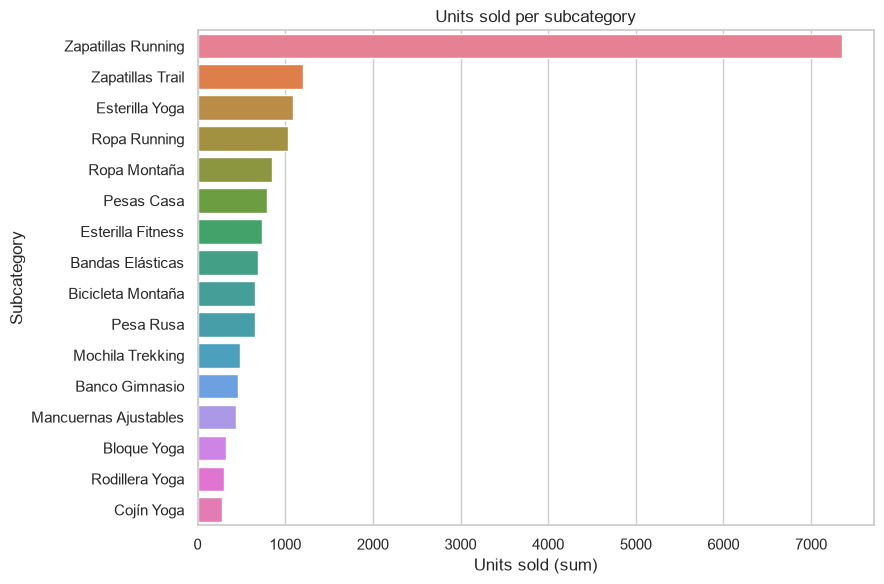

In [18]:
# Sum the units sold per subcategory
unidades_subcategoria = df.groupby("subcategoria", as_index=False)["unidades_vendidas"].sum().sort_values("unidades_vendidas", ascending=False)

# Plot the units sold per subcategory (horizontal bars for readable labels)
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=unidades_subcategoria, y="subcategoria", x="unidades_vendidas", hue="subcategoria", legend=False, ax=ax)
ax.set_title("Units sold per subcategory")
ax.set_xlabel("Units sold (sum)")
ax.set_ylabel("Subcategory")
plt.tight_layout()
plt.show()

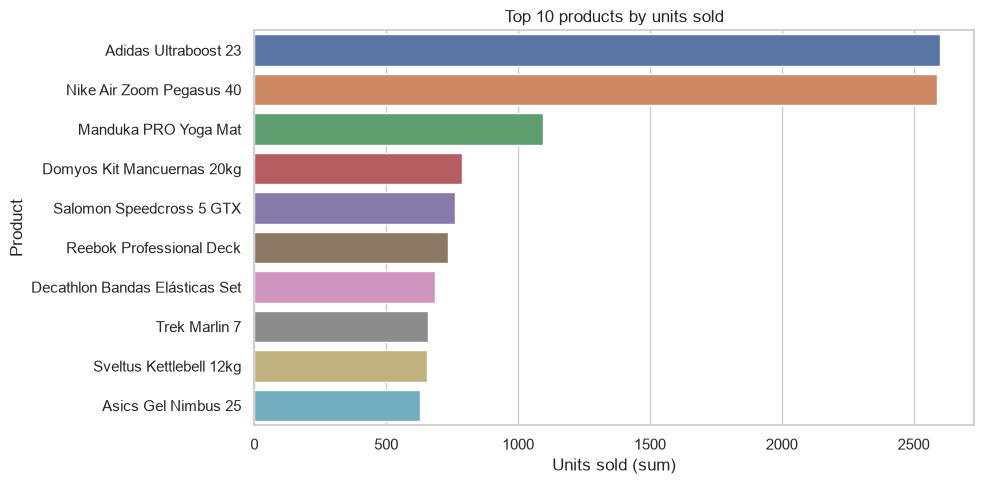

In [19]:
# Sum the units sold per product and keep the top 10
top_productos = df.groupby("nombre", as_index=False)["unidades_vendidas"].sum().nlargest(10, "unidades_vendidas")

# Plot the top 10 products by units sold
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=top_productos, y="nombre", x="unidades_vendidas", hue="nombre", legend=False, ax=ax)
ax.set_title("Top 10 products by units sold")
ax.set_xlabel("Units sold (sum)")
ax.set_ylabel("Product")
plt.tight_layout()
plt.show()

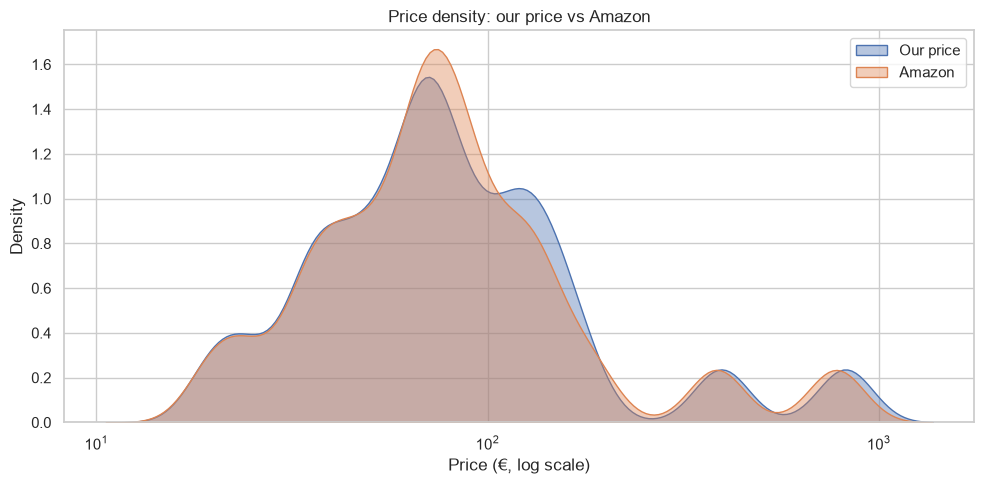

In [20]:
# Plot the density of our sale price vs Amazon price (log scale because prices span from ~20 to ~850)
fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(data=df, x="precio_venta", log_scale=True, fill=True, alpha=0.4, label="Our price", ax=ax)
sns.kdeplot(data=df, x="Amazon", log_scale=True, fill=True, alpha=0.4, label="Amazon", ax=ax)
ax.set_title("Price density: our price vs Amazon")
ax.set_xlabel("Price (€, log scale)")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.show()

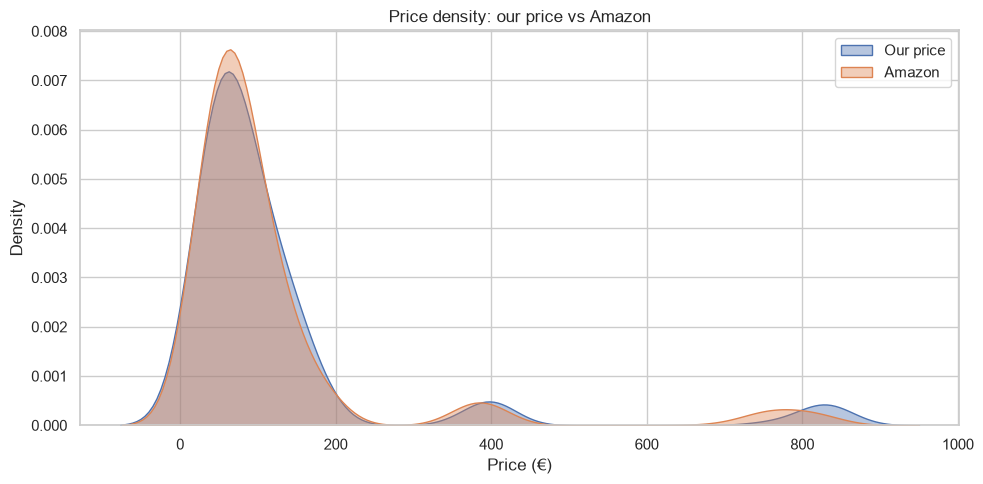

In [21]:
# Create the figure for the density plot with a linear x axis
fig, ax = plt.subplots(figsize=(10, 5))

# Plot the density of our sale price
sns.kdeplot(data=df, x="precio_venta", fill=True, alpha=0.4, label="Our price", ax=ax)

# Plot the density of Amazon's price as the competition reference
sns.kdeplot(data=df, x="Amazon", fill=True, alpha=0.4, label="Amazon", ax=ax)

# Set the title, axis labels and legend
ax.set_title("Price density: our price vs Amazon")
ax.set_xlabel("Price (€)")
ax.set_ylabel("Density")
ax.legend()

# Adjust the layout and show the figure
plt.tight_layout()
plt.show()

# Feature engineering: calendar and temporal variables

In this section we create temporal and calendar features from the `fecha` column of `df`, using the `holidays` library for the Spanish national holidays:

- **Basic date parts**: year, month, day of the month, day of the week, day of the year, week of the year and quarter.
- **Weekend flag**: whether the day is Saturday or Sunday.
- **Holiday features**: whether the day is a Spanish national holiday, and whether it is the eve of a holiday.
- **Shopping events**: Black Friday (day after the 4th Thursday of November) and Cyber Monday (the following Monday), plus the Black Friday week and the signed number of days to Black Friday, which captures the build-up and the aftermath of the campaign.
- **Month position**: whether the day is in the first or last days of the month.

All the binary flags are stored as 0/1 integers so they can be used directly by the models.

In [22]:
# Extract the basic date parts
df["año"] = df["fecha"].dt.year
df["mes"] = df["fecha"].dt.month
df["dia_mes"] = df["fecha"].dt.day
df["dia_semana"] = df["fecha"].dt.dayofweek  # Monday=0 ... Sunday=6
df["dia_año"] = df["fecha"].dt.dayofyear
df["semana_año"] = df["fecha"].dt.isocalendar().week.astype(int)
df["trimestre"] = df["fecha"].dt.quarter

# Flag the weekends (Saturday and Sunday)
df["es_fin_semana"] = (df["dia_semana"] >= 5).astype(int)

# Build the set of Spanish national holidays for the years in the data
festivos_es = set(holidays.Spain(years=df["año"].unique().tolist()).keys())

# Flag the holidays and the eve of a holiday
df["es_festivo"] = df["fecha"].dt.date.isin(festivos_es).astype(int)
df["es_vispera_festivo"] = (df["fecha"] + pd.Timedelta(days=1)).dt.date.isin(festivos_es).astype(int)

# Get the Black Friday date of each year (computed in the EDA section) and map it to every row
black_friday_por_año = pd.Series(black_fridays, index=black_fridays.year)
fecha_black_friday = df["año"].map(black_friday_por_año)

# Flag Black Friday and Cyber Monday (the Monday right after Black Friday)
df["es_black_friday"] = (df["fecha"] == fecha_black_friday).astype(int)
df["es_cyber_monday"] = (df["fecha"] == fecha_black_friday + pd.Timedelta(days=3)).astype(int)

# Flag the Black Friday week (Monday to Sunday) and compute the signed days to Black Friday
df["es_semana_black_friday"] = (df["semana_año"] == fecha_black_friday.dt.isocalendar().week.astype(int)).astype(int)
df["dias_hasta_black_friday"] = (fecha_black_friday - df["fecha"]).dt.days

# Flag the first and last 3 days of the month
df["es_inicio_mes"] = (df["dia_mes"] <= 3).astype(int)
df["es_fin_mes"] = ((df["fecha"].dt.days_in_month - df["dia_mes"]) < 3).astype(int)

# Check the new columns and the flagged dates
cols_calendario = ["fecha", "año", "mes", "dia_mes", "dia_semana", "dia_año", "semana_año", "trimestre", "es_fin_semana",
                   "es_festivo", "es_vispera_festivo", "es_black_friday", "es_cyber_monday", "es_semana_black_friday",
                   "dias_hasta_black_friday", "es_inicio_mes", "es_fin_mes"]
display(df[cols_calendario].drop_duplicates("fecha").query("es_festivo == 1 or es_black_friday == 1 or es_cyber_monday == 1"))
df[cols_calendario].head()

,fecha,año,mes,dia_mes,dia_semana,dia_año,semana_año,trimestre,es_fin_semana,es_festivo,es_vispera_festivo,es_black_friday,es_cyber_monday,es_semana_black_friday,dias_hasta_black_friday,es_inicio_mes,es_fin_mes
168,2021-11-01,2021,11,1,0,305,44,4,0,1,0,0,0,0,25,1,0
768,2021-11-26,2021,11,26,4,330,47,4,0,0,0,1,0,1,0,0,0
840,2021-11-29,2021,11,29,0,333,48,4,0,0,0,0,1,0,-3,0,1
1056,2022-11-01,2022,11,1,1,305,44,4,0,1,0,0,0,0,24,1,0
1632,2022-11-25,2022,11,25,4,329,47,4,0,0,0,1,0,1,0,0,0
1704,2022-11-28,2022,11,28,0,332,48,4,0,0,0,0,1,0,-3,0,1
1944,2023-11-01,2023,11,1,2,305,44,4,0,1,0,0,0,0,23,1,0
2496,2023-11-24,2023,11,24,4,328,47,4,0,0,0,1,0,1,0,0,0
2568,2023-11-27,2023,11,27,0,331,48,4,0,0,0,0,1,0,-3,0,0
2832,2024-11-01,2024,11,1,4,306,44,4,0,1,0,0,0,0,28,1,0


,fecha,año,mes,dia_mes,dia_semana,dia_año,semana_año,trimestre,es_fin_semana,es_festivo,es_vispera_festivo,es_black_friday,es_cyber_monday,es_semana_black_friday,dias_hasta_black_friday,es_inicio_mes,es_fin_mes
0,2021-10-25,2021,10,25,0,298,43,4,0,0,0,0,0,0,32,0,0
1,2021-10-25,2021,10,25,0,298,43,4,0,0,0,0,0,0,32,0,0
2,2021-10-25,2021,10,25,0,298,43,4,0,0,0,0,0,0,32,0,0
3,2021-10-25,2021,10,25,0,298,43,4,0,0,0,0,0,0,32,0,0
4,2021-10-25,2021,10,25,0,298,43,4,0,0,0,0,0,0,32,0,0


# Feature engineering: lags and moving average

In this section we create the autoregressive features of the units sold:

- **Lags 1 to 7** of `unidades_vendidas`: the units sold 1 to 7 days before, for the same product.
- **7-day moving average** of `unidades_vendidas`: the mean of the previous 7 days (the current day is excluded to avoid data leakage).

Each feature is computed separately for each product and each year, so the last days of November of one year are never mixed with the first days of October of the next one. The first 7 days of every product and year cannot have all the values, so the rows with nulls in any of the new variables are dropped.

In [23]:
# Sort by product and date so the shifts follow the time order inside each product
df = df.sort_values(["producto_id", "fecha"]).reset_index(drop=True)

# Group by product and year so the lags never mix different campaigns
grupos = df.groupby(["producto_id", "año"])["unidades_vendidas"]

# Create the lags 1 to 7 of the units sold
cols_lags = []
for lag in range(1, 8):
    df[f"unidades_lag_{lag}"] = grupos.shift(lag)
    cols_lags.append(f"unidades_lag_{lag}")

# Create the 7-day moving average of the previous days (shifted by 1 to exclude the current day)
df["unidades_media_movil_7"] = grupos.transform(lambda s: s.shift(1).rolling(window=7).mean())

# Count the nulls created in the new variables and drop those rows
cols_nuevas = cols_lags + ["unidades_media_movil_7"]
print("Rows before:", len(df))
print(df[cols_nuevas].isna().sum())
df = df.dropna(subset=cols_nuevas)

# Restore the original order (date and product) and reset the index
df = df.sort_values(["fecha", "producto_id"]).reset_index(drop=True)
print("Rows after:", len(df))

# Check the new variables
df[["fecha", "producto_id", "unidades_vendidas"] + cols_nuevas].head()

Rows before: 3552
unidades_lag_1             96
unidades_lag_2            192
unidades_lag_3            288
unidades_lag_4            384
unidades_lag_5            480
unidades_lag_6            576
unidades_lag_7            672
unidades_media_movil_7    672
dtype: int64
Rows after: 2880


,fecha,producto_id,unidades_vendidas,unidades_lag_1,unidades_lag_2,unidades_lag_3,unidades_lag_4,unidades_lag_5,unidades_lag_6,unidades_lag_7,unidades_media_movil_7
0,2021-11-01,PROD_001,7,9.0,12.0,12.0,7.0,8.0,8.0,6.0,8.857143
1,2021-11-01,PROD_002,10,10.0,12.0,9.0,8.0,8.0,10.0,10.0,9.571429
2,2021-11-01,PROD_003,2,3.0,3.0,3.0,2.0,3.0,2.0,2.0,2.571429
3,2021-11-01,PROD_004,2,3.0,3.0,2.0,2.0,2.0,2.0,2.0,2.285714
4,2021-11-01,PROD_005,2,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.000000


In [24]:
df.groupby('año').size()

año
2021    720
2022    720
2023    720
2024    720
dtype: int64

In [25]:
df[df["producto_id"] == "PROD_001"][["fecha", "unidades_vendidas", "unidades_lag_1"]].head(3)

,fecha,unidades_vendidas,unidades_lag_1
0,2021-11-01,7,9.0
24,2021-11-02,10,7.0
48,2021-11-03,11,10.0


In [30]:
# Create the discount percentage: (sale price - base price) / base price * 100 (negative values are discounts)
df["descuento_porcentaje"] = (df["precio_venta"] - df["precio_base"]) / df["precio_base"] * 100

# Check the new variable
print(df["descuento_porcentaje"].describe())
df[["fecha", "producto_id", "precio_base", "precio_venta", "descuento_porcentaje"]].head()

count    2880.000000
mean       -1.354958
std         3.814963
min       -15.000000
25%        -2.334036
50%        -0.554196
75%         1.261538
max         2.991304
Name: descuento_porcentaje, dtype: float64


,fecha,producto_id,precio_base,precio_venta,descuento_porcentaje
0,2021-11-01,PROD_001,115,115.07,0.060870
1,2021-11-01,PROD_002,135,136.00,0.740741
2,2021-11-01,PROD_003,85,85.14,0.164706
3,2021-11-01,PROD_004,75,76.74,2.320000
4,2021-11-01,PROD_005,35,34.89,-0.314286


In [31]:
# Create the average price of the competitors (Amazon, Decathlon and Deporvillage)
cols_competidores = ["Amazon", "Decathlon", "Deporvillage"]
df["precio_competencia"] = df[cols_competidores].mean(axis=1)

# Create the price ratio: our sale price divided by the average competitors' price
df["ratio_precio"] = df["precio_venta"] / df["precio_competencia"]

# Drop the individual competitors' price columns
df = df.drop(columns=cols_competidores)

# Check the new variables
print(df["ratio_precio"].describe())
df[["fecha", "producto_id", "precio_venta", "precio_competencia", "ratio_precio"]].head()

count    2880.000000
mean        1.033537
std         0.059630
min         0.823112
25%         1.000149
50%         1.030406
75%         1.061185
max         1.303042
Name: ratio_precio, dtype: float64


,fecha,producto_id,precio_venta,precio_competencia,ratio_precio
0,2021-11-01,PROD_001,115.07,95.353333,1.206775
1,2021-11-01,PROD_002,136.00,113.393333,1.199365
2,2021-11-01,PROD_003,85.14,83.276667,1.022375
3,2021-11-01,PROD_004,76.74,71.843333,1.068158
4,2021-11-01,PROD_005,34.89,33.490000,1.041804


In [33]:
# Create a copy of the descriptive variables with the _h suffix, so the originals are kept
cols_h = ["nombre_h", "categoria_h", "subcategoria_h"]
df["nombre_h"] = df["nombre"]
df["categoria_h"] = df["categoria"]
df["subcategoria_h"] = df["subcategoria"]

# Apply one-hot encoding to the copied variables (0/1 integer columns, one per value)
df = pd.get_dummies(df, columns=cols_h, dtype=int)

# Check the new one-hot columns
cols_onehot = [col for col in df.columns if col.startswith(tuple(cols_h))]
print(len(cols_onehot), "one-hot columns created")
df[cols_onehot].head()

44 one-hot columns created


,nombre_h_Adidas Own The Run Jacket,nombre_h_Adidas Ultraboost 23,nombre_h_Asics Gel Nimbus 25,nombre_h_Bowflex SelectTech 552,nombre_h_Columbia Silver Ridge,nombre_h_Decathlon Bandas Elásticas Set,nombre_h_Domyos BM900,nombre_h_Domyos Kit Mancuernas 20kg,nombre_h_Gaiam Premium Yoga Block,nombre_h_Liforme Yoga Pad,...,subcategoria_h_Esterilla Yoga,subcategoria_h_Mancuernas Ajustables,subcategoria_h_Mochila Trekking,subcategoria_h_Pesa Rusa,subcategoria_h_Pesas Casa,subcategoria_h_Rodillera Yoga,subcategoria_h_Ropa Montaña,subcategoria_h_Ropa Running,subcategoria_h_Zapatillas Running,subcategoria_h_Zapatillas Trail
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


In [34]:
# Import Path to handle the folder and file paths
from pathlib import Path

# Create the models folder (relative to the notebooks folder) if it does not exist
ruta_modelos = Path("../models")
ruta_modelos.mkdir(parents=True, exist_ok=True)

# Save the one-hot columns, in the same order, in a CSV with a single column named "columna" (no index)
ruta_onehot = ruta_modelos / "onehot_columnas.csv"
pd.DataFrame({"columna": cols_onehot}).to_csv(ruta_onehot, index=False)

# Check the saved file
print(pd.read_csv(ruta_onehot).shape)

(44, 1)


In [35]:
def aplicar_onehot(df_nuevo):
    """Apply the saved one-hot encoding to new data, returning exactly the saved columns in the saved order."""
    # Build an auxiliary dataframe with only the descriptive variables, renamed with the _h suffix
    auxiliar = df_nuevo[["nombre", "categoria", "subcategoria"]].rename(
        columns={"nombre": "nombre_h", "categoria": "categoria_h", "subcategoria": "subcategoria_h"}
    )

    # Apply one-hot encoding only to the auxiliary dataframe (df_nuevo is not modified)
    codificado = pd.get_dummies(auxiliar, dtype=int)

    # Read the saved columns and align: new categories are ignored and missing ones are filled with zeros
    columnas_guardadas = pd.read_csv(ruta_onehot)["columna"].tolist()
    return codificado.reindex(columns=columnas_guardadas, fill_value=0)

In [36]:
# Check a) the function reproduces the same 44 columns and the same values as df[cols_onehot]
completo = aplicar_onehot(df)
print("a) same columns and values:", completo.shape[1] == 44 and completo.equals(df[cols_onehot]))

# Check b) a small sample with missing categories still returns the 44 columns in the same order
muestra = aplicar_onehot(df.head(5))
print("b) same 44 columns in the same order:", muestra.shape[1] == 44 and muestra.columns.tolist() == cols_onehot)

a) same columns and values: True
b) same 44 columns in the same order: True
